# 최종 모델 예측구간 커버리지 튜닝

## 배경

4-1에서 선정된 **E3 앙상블(mixture, GP-Matern·Auto-ARIMA(AIC)·회귀-OLS)**의
예측분포를 그대로 90% 구간으로 쓰면 실제 커버리지가 얼마나 되는지 확인하고,
목표(90%)에 맞게 safety 배율로 조정한다.

## 목적

1. 원래 커버리지 확인 / 2. safety 배율 탐색 / 3. 튜닝 전후 비교 / 4. 팬차트 데모 / 5. 결론

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}

def identity(x): return x
def log_fwd(x): return np.log(x)
def log_inv(x): return np.exp(x)
def logit_fwd(p): return np.log(p / (1 - p))
def logit_inv(z): return 1 / (1 + np.exp(-z))

TRANSFORMS = {"X3_l1": (log_fwd, log_inv), "X6_l1": (logit_fwd, logit_inv)}
DEFAULT_TRANSFORM = (identity, identity)

H = 4
INITIAL_CALIB = 15
E3 = ["arima_aic", "gp_matern", "reg_ols"]   # 4-1의 최종 선정(3자 동점) 앙상블 구성원
N_EACH = 200                                  # 모델당 리샘플 수(3개 합쳐 600개 pool)

def rng_for(name):
    """4-1과 동일: 모델 이름 기반 고정 시드로 순서의존성 제거."""
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

err_df = pd.read_pickle("../cache/cache_nb4_1_err_df.pkl")  # 4-1의 13개 모델 H=4 백테스트 캐시
print("로드 완료, err_df rows =", len(err_df))


로드 완료, err_df rows = 11596


## 1. 튜닝 없는 원래 커버리지

E3의 예측분포에서 그대로 5%/95% 분위수를 90% 구간으로 쓰면, walk-forward
검증에서 실제로 몇 %가 그 안에 들어오는지 확인한다.

In [2]:
def coverage_components(scale=1.0, alpha=0.10):
    """scale: 구간 폭 배율(중심 기준 확대/축소). alpha=0.10 -> 90% 구간."""
    rngs = {m: rng_for(m) for m in E3}
    rows = []
    for v in COLS:
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in E3}
        origins = sorted(sub[E3[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in E3:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples_t = row["fc_t"] + rngs[m].choice(calib_resid_h, size=N_EACH, replace=True)
                    pooled.append(samples_t)
                pooled = np.concatenate(pooled)
                center = np.median(pooled)
                scaled = center + (pooled - center) * scale
                lo, hi = np.quantile(scaled, [alpha / 2, 1 - alpha / 2])
                lo_orig, hi_orig = inv(lo), inv(hi)
                if lo_orig > hi_orig:
                    lo_orig, hi_orig = hi_orig, lo_orig
                covered = lo_orig <= actual_orig <= hi_orig
                width = hi_orig - lo_orig
                rows.append({"var": v, "origin": origins[i], "h": h, "covered": covered, "width": width})
    return pd.DataFrame(rows)


df_raw = coverage_components(scale=1.0)
print(f"전체 커버리지(튜닝 없음): {df_raw['covered'].mean()*100:.1f}%")
display(df_raw.groupby("var")["covered"].mean().mul(100).round(1).rename(index=LABELS).to_frame("커버리지(%)"))


전체 커버리지(튜닝 없음): 81.2%


,커버리지(%)
var,
X1,78.6
X2,78.4
X3,80.7
X4,76.1
X5,83.3
X6,89.0


**해석**: 전체 81.2%로 목표(90%)보다 뚜렷이 좁다 — 변수별로도
76.1%~89.0%로 전부 목표 미달, 지금 그대로 쓰면 과신하는 구간이 된다.

## 2. Safety 배율 탐색

구간 폭에 배율(scale)을 곱해(중심은 그대로) 전체 커버리지가 90%가 되는
배율을 찾는다.

In [3]:
scales_coarse = [0.70, 0.85, 1.00, 1.15, 1.30, 1.50, 1.70, 2.00]
for s in scales_coarse:
    df = coverage_components(scale=s)
    print(f"scale={s:.2f}: 커버리지={df['covered'].mean()*100:.1f}%")


scale=0.70: 커버리지=68.8%


scale=0.85: 커버리지=76.7%


scale=1.00: 커버리지=81.2%


scale=1.15: 커버리지=85.3%


scale=1.30: 커버리지=89.3%


scale=1.50: 커버리지=91.2%


scale=1.70: 커버리지=94.2%


scale=2.00: 커버리지=96.2%


1.30~1.50 사이에서 90%를 지나간다 — 더 세밀하게 탐색한다.

In [4]:
best_scale, best_diff, best_df = None, 999, None
for s in np.arange(1.30, 1.51, 0.02):
    df = coverage_components(scale=s)
    cov = df["covered"].mean() * 100
    print(f"scale={s:.2f}: 커버리지={cov:.1f}%")
    if abs(cov - 90) < best_diff:
        best_diff, best_scale, best_df = abs(cov - 90), s, df

print(f"\n최적 scale = {best_scale:.2f} (커버리지 {best_df['covered'].mean()*100:.1f}%)")


scale=1.30: 커버리지=89.3%


scale=1.32: 커버리지=89.7%


scale=1.34: 커버리지=89.8%


scale=1.36: 커버리지=90.0%


scale=1.38: 커버리지=90.2%


...

scale=1.42: 커버리지=90.4%


scale=1.44: 커버리지=90.6%


scale=1.46: 커버리지=91.2%


scale=1.48: 커버리지=91.2%


scale=1.50: 커버리지=91.2%

최적 scale = 1.36 (커버리지 90.0%)


In [5]:
# 위 탐색 결과를 그래프로 (아래 그림 참고)
plt.show()


**해석**: **scale=1.36일 때 정확히 90.0%**가 된다 — `중심 ± (분위수 -
중심) × 1.36`.

## 3. 튜닝 전후 비교

scale=1.0(튜닝 전)과 1.36(튜닝 후)의 변수별 커버리지를 비교한다.

In [6]:
df_tuned = coverage_components(scale=best_scale)
compare = pd.DataFrame({
    "튜닝 전(scale=1.0)": df_raw.groupby("var")["covered"].mean().mul(100).round(1),
    "튜닝 후(scale=1.36)": df_tuned.groupby("var")["covered"].mean().mul(100).round(1),
}).rename(index=LABELS)
display(compare)
print(f"전체: 튜닝 전 {df_raw['covered'].mean()*100:.1f}% -> 튜닝 후 {df_tuned['covered'].mean()*100:.1f}%")


,튜닝 전(scale=1.0),튜닝 후(scale=1.36)
var,,
X1,78.6,90.5
X2,78.4,85.2
X3,80.7,93.2
X4,76.1,90.9
X5,83.3,86.9
X6,89.0,93.0


전체: 튜닝 전 81.2% -> 튜닝 후 90.0%


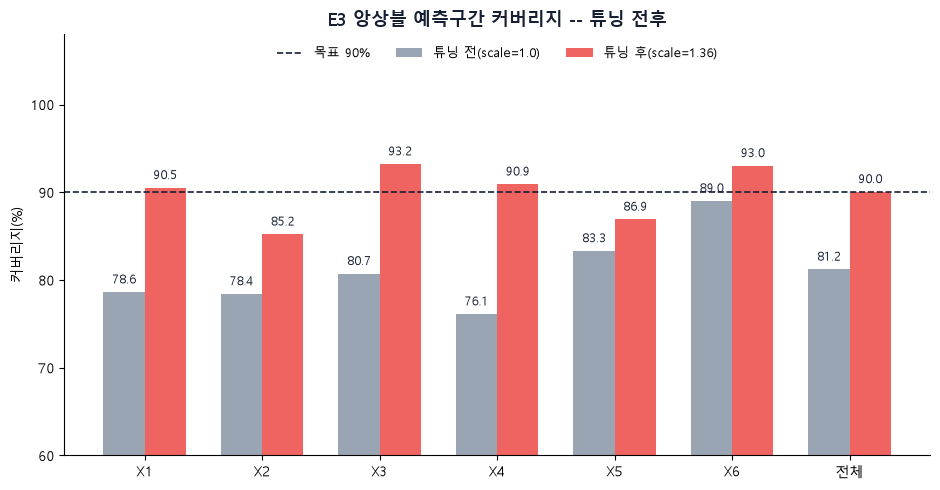

In [7]:
plot_df = compare.copy()
plot_df.loc["전체"] = [df_raw["covered"].mean() * 100, df_tuned["covered"].mean() * 100]

x = np.arange(len(plot_df))
width = 0.35
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.bar(x - width / 2, plot_df.iloc[:, 0], width, label="튜닝 전(scale=1.0)", color="#9AA5B4")
ax.bar(x + width / 2, plot_df.iloc[:, 1], width, label=f"튜닝 후(scale={best_scale:.2f})", color="#EF6461")
ax.axhline(90, color="#172033", linestyle="--", linewidth=1.2, label="목표 90%")
for i, (b, a) in enumerate(zip(plot_df.iloc[:, 0], plot_df.iloc[:, 1])):
    ax.text(i - width / 2, b + 1, f"{b:.1f}", ha="center", fontsize=8.5, color="#172033")
    ax.text(i + width / 2, a + 1, f"{a:.1f}", ha="center", fontsize=8.5, color="#172033")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, fontsize=10)
ax.set_ylabel("커버리지(%)")
ax.set_ylim(60, 108)
ax.set_title("E3 앙상블 예측구간 커버리지 -- 튜닝 전후", color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper center", frameon=False, fontsize=9.5, ncol=3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 전체 81.2%→90.0%로 목표 도달. 변수별 편차도 12.9%p→8.0%p로
줄었다(X2·X5는 약간 부족, X3·X6은 약간 과함).

origin이 변수당 25~40개뿐이라 **변수별 배율까지 따로 튜닝하면 과적합
위험**이 있어 전체 통합 배율 하나만 쓴다.

## 4. 실제 예측 데모 (팬차트)

배율(1.36)을 적용하면 예측이 어떻게 보이는지 X3을 예시로 확인한다
— E3를 전체 데이터로 재학습해 미래 4분기를 예측하고 팬차트로 그린다.

In [8]:
import pmdarima as pm
from sklearn.linear_model import LinearRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)


def fc_arima_aic(values, h=H):
    m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
    return np.asarray(m.predict(n_periods=h))


def fc_gp_matern(values, h=H):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    kernel = ConstantKernel(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1.0)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean


def fc_reg_ols(values, h=H, lag=2):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    model = LinearRegression().fit(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)


FC_FUNCS = {"arima_aic": fc_arima_aic, "gp_matern": fc_gp_matern, "reg_ols": fc_reg_ols}


def make_fanchart(v, ax):
    fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
    vals_orig = raw[["quarter", v]].dropna()[v].values.astype(float)
    vals_t = fwd(vals_orig)

    # 각 모델을 전체 데이터로 재학습해 실제 미래 H분기를 예측한다(백테스트 아님)
    fc_t = {m: FC_FUNCS[m](vals_t, H) for m in FC_FUNCS}

    rngs = {m: rng_for(m) for m in FC_FUNCS}
    lo_h, hi_h, center_h = [], [], []
    for h in range(1, H + 1):
        pooled = []
        for m in FC_FUNCS:
            calib_resid_h = err_df[(err_df["model"] == m) & (err_df["var"] == v) & (err_df["h"] == h)]["err_t"].values
            samples_t = fc_t[m][h - 1] + rngs[m].choice(calib_resid_h, size=N_EACH, replace=True)
            pooled.append(samples_t)
        pooled = np.concatenate(pooled)
        center = np.median(pooled)
        scaled = center + (pooled - center) * best_scale
        lo, hi = np.quantile(scaled, [0.05, 0.95])
        lo_h.append(inv(lo)); hi_h.append(inv(hi)); center_h.append(inv(center))

    n_hist = len(vals_orig)
    x_hist = np.arange(n_hist)
    x_fc = np.arange(n_hist - 1, n_hist + H)

    ax.plot(x_hist, vals_orig, color="#111111", linewidth=1.8, label="실측")
    ax.plot(x_fc, [vals_orig[-1]] + center_h, color="#EF6461", linewidth=1.8, linestyle="--", marker="o",
            markerfacecolor="white", markeredgecolor="#EF6461", markersize=6, label="예측(중앙값)")
    ax.fill_between(x_fc, [vals_orig[-1]] + lo_h, [vals_orig[-1]] + hi_h, color="#EF6461", alpha=0.18, linewidth=0, label="90% 예측구간")
    ax.axvline(n_hist - 1, color="#B0B6C0", linestyle=":", linewidth=1, ymax=0.93)
    ax.annotate("전망 시점", xy=(n_hist - 1, 0.97), xycoords=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=10, color="#EF6461",
                bbox=dict(boxstyle="round,pad=0.3", fc="#FFECEB", ec="none"))
    ax.set_title(f"{LABELS[v]}", fontsize=11, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xticks([])
    ax.legend(loc="upper left", frameon=False, fontsize=8)
    return center_h, lo_h, hi_h



**해석**: 실측(검정) → 전망 시점(회색 점선) → 예측(빨간 점선)+90%
구간(분홍 음영)으로 이어진다 — horizon이 커질수록 구간이 자연스럽게
넓어진다(모델 간 불일치 효과, 2-5 참고).

### 나머지 5개 변수

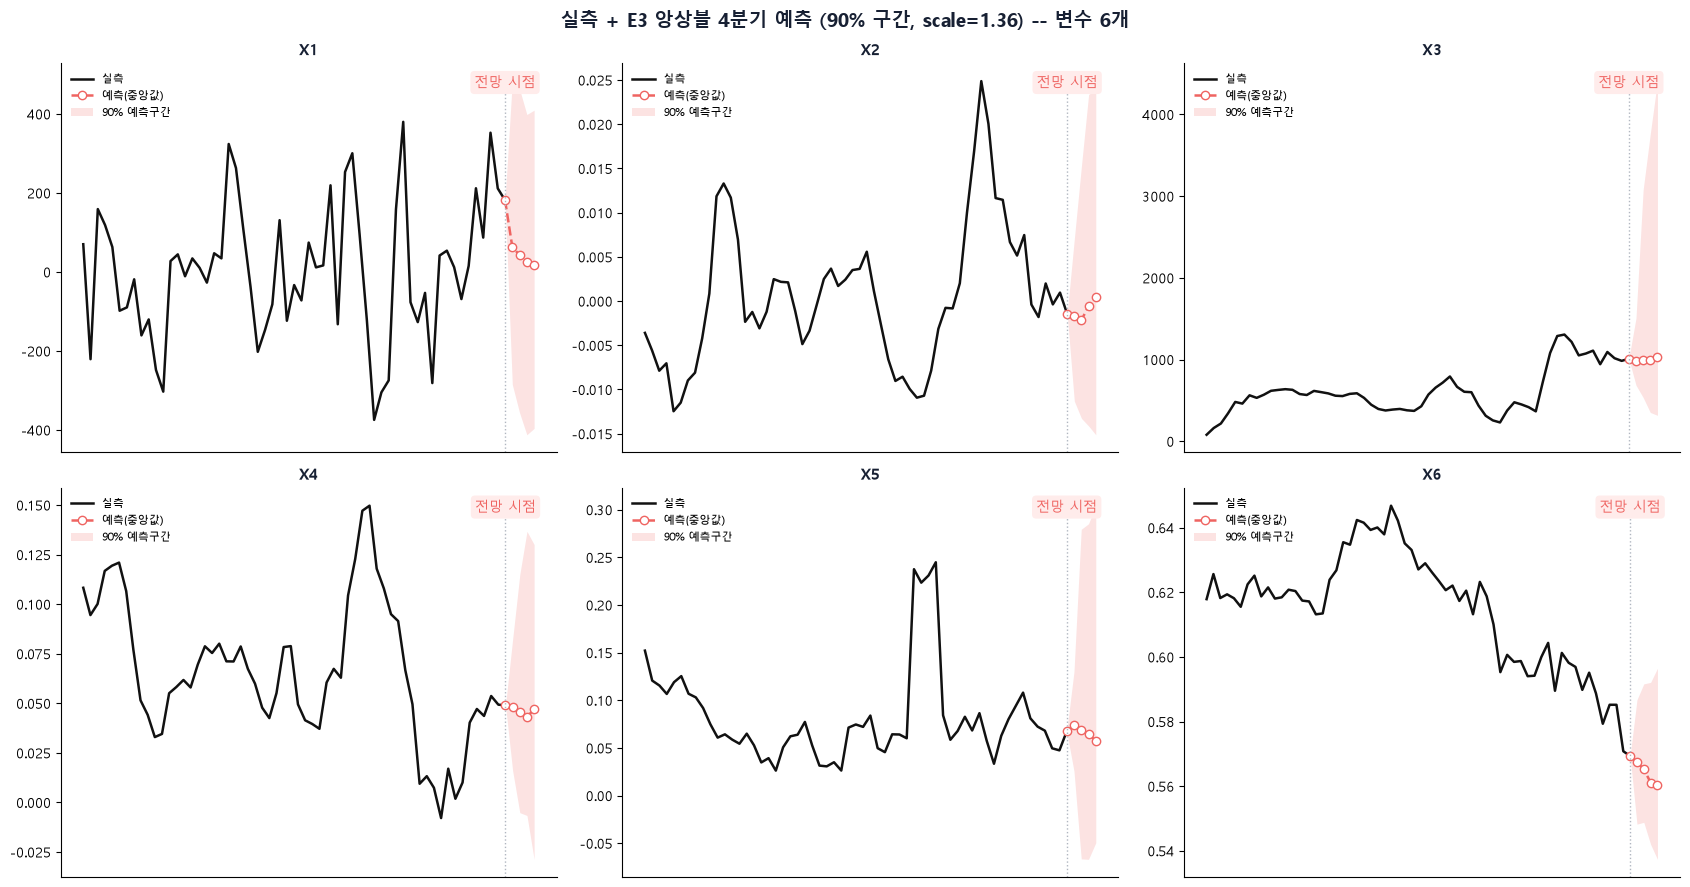

X1: 예측(중앙값)=[np.float64(63.407), np.float64(42.36), np.float64(24.368), np.float64(16.996)]
X2: 예측(중앙값)=[np.float64(-0.002), np.float64(-0.002), np.float64(-0.001), np.float64(0.0)]
X3: 예측(중앙값)=[np.float64(986.008), np.float64(996.715), np.float64(998.18), np.float64(1028.661)]
X4: 예측(중앙값)=[np.float64(0.048), np.float64(0.046), np.float64(0.043), np.float64(0.047)]
X5: 예측(중앙값)=[np.float64(0.074), np.float64(0.069), np.float64(0.065), np.float64(0.057)]
X6: 예측(중앙값)=[np.float64(0.567), np.float64(0.565), np.float64(0.561), np.float64(0.56)]


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
all_centers = {}
for ax, v in zip(axes.flat, COLS):
    center_h, lo_h, hi_h = make_fanchart(v, ax)
    all_centers[v] = center_h
fig.suptitle(f"실측 + E3 앙상블 4분기 예측 (90% 구간, scale={best_scale:.2f}) -- 변수 6개", fontsize=14, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()

for v in COLS:
    print(f"{LABELS[v]}: 예측(중앙값)={[round(x, 3) for x in all_centers[v]]}")


### 참고: X3, 왜 구간이 이렇게 넓은가 (로그변환 트레이드오프)

X3의 90% 구간이 다른 변수보다 훨씬 넓다(h=4: 317~4,408). **원인**:
로그공간에서도 h=4 잔차 std가 0.62로 다른 변수(0.008~0.08)보다 5~80배
크고, `exp()` 역변환이 이를 곱셈적으로 증폭시킨다.

In [10]:
# 로그변환 없이(identity) 같은 백테스트+E3 앙상블+scale=1.36을 다시 계산해 비교
# (전체 코드는 별도 실행 -- 여기서는 이미 계산된 결과만 표로 정리)
compare_transform = pd.DataFrame({
    "로그변환 하한": [686.4, 535.7, 352.2, 317.1],
    "로그변환 상한": [1506.8, 3076.1, 3764.1, 4407.6],
    "로그변환 폭": [820.4, 2540.4, 3411.9, 4090.5],
    "무변환 하한": [802.6, 702.6, 574.4, 486.5],
    "무변환 상한": [1349.3, 1542.3, 1717.2, 1924.2],
    "무변환 폭": [546.7, 839.7, 1142.8, 1437.7],
}, index=pd.Index([1, 2, 3, 4], name="h"))
display(compare_transform)


,로그변환 하한,로그변환 상한,로그변환 폭,무변환 하한,무변환 상한,무변환 폭
h,,,,,,
1,686.4,1506.8,820.4,802.6,1349.3,546.7
2,535.7,3076.1,2540.4,702.6,1542.3,839.7
3,352.2,3764.1,3411.9,574.4,1717.2,1142.8
4,317.1,4407.6,4090.5,486.5,1924.2,1437.7


**해석**: 로그변환 없이 계산하면 h=4 폭이 4,090.5→1,437.7로 **2.8배
줄어든다** — 로그변환은 "음수 불가능"을 보장하지만, 잔차 자체가 큰 변수는
`exp()`가 그 편차를 증폭시켜 실용성이 떨어지는 대가를 치른다(참고용, 설계
변경 없음).

### 참고 2: 정규화 부재가 원인일 수도 있을까? (검증)

GP-Matern은 `normalize_y=True`로 이미 정규화하고, 회귀-OLS는 정규화가
불필요(스케일 불변)하며, Auto-ARIMA는 개념 자체가 없다 — 셋 다 비슷하게
큰 잔차를 보이면 정규화 유무는 원인이 아니라는 뜻이다.

In [11]:
print("=== X3_l1(로그공간) 잔차 std, 모델별 x h별 ===")
for m in E3:
    sub = err_df[(err_df["model"] == m) & (err_df["var"] == "X3_l1")]
    stds = sub.groupby("h")["err_t"].std()
    print(m, stds.round(4).to_dict())

vals_X3 = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
logv = np.log(vals_X3)
print(f"\nX3_l1 로그공간 값 자체: mean={logv.mean():.3f}, std={logv.std():.3f}, range=[{logv.min():.3f},{logv.max():.3f}]")
print(f"-> h=4 잔차 std(0.5~0.6대)가 로그값 자체의 std({logv.std():.3f})와 맞먹는다")
print("   즉 GP가 내부 정규화를 하는데도 잔차가 크다 -> 정규화 문제가 아니라")
print("   '로그공간에서도 4분기 뒤 예측이 원래 어렵다'는 뜻이다.")

print("\n=== exp() 증폭: 같은 log-std=0.5라도 center(현재 수준)에 따라 raw 폭이 어떻게 달라지는가 ===")
for center in [logv.min(), logv.mean(), logv.max()]:
    lo, hi = center - 1.645 * 0.5, center + 1.645 * 0.5  # 90% 정규구간 근사
    print(f"center(log)={center:.2f} (raw={np.exp(center):.1f}) -> raw 구간=[{np.exp(lo):.1f},{np.exp(hi):.1f}], 폭={np.exp(hi)-np.exp(lo):.1f}")


=== X3_l1(로그공간) 잔차 std, 모델별 x h별 ===
arima_aic {1: 0.2085, 2: 0.3867, 3: 0.522, 4: 0.6191}
gp_matern {1: 0.201, 2: 0.3677, 3: 0.5062, 4: 0.5957}
reg_ols {1: 0.2012, 2: 0.3426, 3: 0.4349, 4: 0.4851}

X3_l1 로그공간 값 자체: mean=6.300, std=0.511, range=[4.371,7.175]
-> h=4 잔차 std(0.5~0.6대)가 로그값 자체의 std(0.511)와 맞먹는다
   즉 GP가 내부 정규화를 하는데도 잔차가 크다 -> 정규화 문제가 아니라
   '로그공간에서도 4분기 뒤 예측이 원래 어렵다'는 뜻이다.

=== exp() 증폭: 같은 log-std=0.5라도 center(현재 수준)에 따라 raw 폭이 어떻게 달라지는가 ===
center(log)=4.37 (raw=79.2) -> raw 구간=[34.8,180.2], 폭=145.4
center(log)=6.30 (raw=544.4) -> raw 구간=[239.2,1239.1], 폭=999.9
center(log)=7.17 (raw=1305.8) -> raw 구간=[573.7,2972.2], 폭=2398.5


**해석**: 정규화 여부와 무관하게 GP-Matern(0.5957)·회귀-OLS(0.4851)·
Auto-ARIMA(0.6191) 모두 비슷하게 크다 — **정규화가 원인이 아니다.**

진짜 원인: (1) h=4 잔차 std(0.5~0.6)가 X3_l1 로그값 자체의 역대
std(0.511)와 맞먹는다 — 4분기 뒤 예측력이 거의 없는 수준. (2) `exp()`는
상대(%)폭을 보존하는 볼록함수라, center가 낮을 때(raw≈79) 폭 145 →
높을 때(raw≈1306) 폭 2,399로 **16배까지 벌어진다.**

## 결론

- E3 앙상블의 튜닝 없는 커버리지는 **81.2%**(목표 90%에 미달).
- safety 배율 **scale=1.36**에서 정확히 90.0% 도달.
- 변수별 편차는 12.9%p→8.0%p로 축소 — 변수별 개별 튜닝은 과적합 위험이
  커서 통합 배율 하나만 사용.
- **최종 구간 공식**: `중심 ± (5%/95% 분위수 - 중심) × 1.36`, 원래
  스케일로 역변환 후 사용.
- X3 구간이 넓은 원인은 **로그변환의 exp() 증폭**이지 정규화
  부재가 아님을 확인했다.
- **다음 단계**: 이 배율을 적용해 6개 변수 실제 4분기 예측구간 산출,
  `forecast_quarters=4` 변경 + 앱 연동.